<a href="https://colab.research.google.com/github/hanviol/ev-spare-parts-import-prioritization/blob/main/Azarya_Melkamu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EV Spare-Parts Import Prioritization

Which EV replacement parts should a new importer in Ethiopia stock first?

1. Load and clean EV listings from five Ethiopian marketplaces
2. Select three vehicles with an explainable score
3. Score 10 parts for each vehicle and recommend the top 5

Raw data: releases [`raw-vehicles-2026-11-18`](https://github.com/hanviol/ev-spare-parts-import-prioritization/releases/tag/raw-vehicles-2026-11-18)
and [`raw-parts-2026-11-18`](https://github.com/hanviol/ev-spare-parts-import-prioritization/releases/tag/raw-parts-2026-11-18),
collected with the scrapers in [`collect/`](https://github.com/hanviol/ev-spare-parts-import-prioritization/tree/main/collect).

> Listing counts show marketplace visibility, not sales.

## 1. Setup

In [1]:
import hashlib
import io
import os
import re

import matplotlib.pyplot as plt
import pandas as pd
import requests

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

REPO = "hanviol/ev-spare-parts-import-prioritization"
RAW_TAG = "raw-vehicles-2026-11-18"
PARTS_TAG = "raw-parts-2026-11-18"

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Load raw data

Files are downloaded from the release and checked against `checksums.txt`.

In [2]:
def download(tag, name):
    response = requests.get(f"https://github.com/{REPO}/releases/download/{tag}/{name}", timeout=300)
    response.raise_for_status()
    return response.content


def load_release(tag, names):
    expected = {}
    for line in download(tag, "checksums.txt").decode("utf-8").strip().splitlines():
        digest, name = line.split("  ")
        expected[name] = digest

    tables = {}
    for name in names:
        content = download(tag, name)
        if hashlib.sha256(content).hexdigest() != expected[name]:
            raise ValueError(f"{name} does not match its checksum")
        tables[name] = pd.read_csv(io.BytesIO(content), dtype=str)
        print(f"{name:<26} {len(tables[name]):>6} rows   checksum OK")
    return tables


raw = load_release(RAW_TAG, ["listings_adey.csv", "listings_jiji.csv", "listings_afromekina.csv",
                             "listings_mekina.csv", "listings_gezat.csv"])

adey = raw["listings_adey.csv"]
jiji = raw["listings_jiji.csv"]
afro = raw["listings_afromekina.csv"]
mekina = raw["listings_mekina.csv"]
gezat = raw["listings_gezat.csv"]

listings_adey.csv            8366 rows   checksum OK


listings_jiji.csv            3787 rows   checksum OK


listings_afromekina.csv       425 rows   checksum OK


listings_mekina.csv            58 rows   checksum OK


listings_gezat.csv             26 rows   checksum OK


## 3. Cleaning

All sources become one table: `source, listing_id, title, model, price_etb, year, mileage_km, seller`.

### 3.1 Model names

Titles are matched against patterns, specific names first (`yuan up` before `yuan`).
Titles with DM-i, DM-p, PHEV, plug-in or hybrid are plug-in hybrids.

In [3]:
MODEL_PATTERNS = [
    ("BYD Seagull", r"sea ?gull|segull|seagul|dolphin mini|atto ?1\b"),
    ("BYD Yuan Up", r"yuan ?up|atto ?2\b"),
    ("BYD Yuan Plus", r"yuan ?plus|yuan ?pluse|yuan ?blus|atto ?3\b"),
    ("BYD e2", r"\be2\b"),
    ("BYD Dolphin", r"dolphin"),
    ("BYD Sealion", r"sea ?lion"),
    ("BYD Seal", r"\bseal\b"),
    ("BYD Song Plus", r"song ?plus|song ?pluse"),
    ("BYD Song L", r"song ?l\b"),
    ("BYD Tang", r"\btang\b"),
    ("BYD Qin Plus", r"\bqin\b"),
    ("BYD Leopard 3", r"(leopard|lepard) ?0?3\b"),
    ("BYD Leopard 5/7/8", r"(leopard|lepard) ?0?[578]\b|titanium"),
    ("Toyota bZ4X", r"bz ?4 ?x"),
    ("Toyota bZ3X", r"bz ?3 ?x"),
    ("Toyota bZ3", r"bz ?3\b"),
    ("Toyota bZ5", r"bz ?5\b"),
    ("VW ID.4", r"\bid ?4\b"),
    ("VW ID.6", r"\bid ?6\b"),
    ("VW ID.3", r"\bid ?3\b"),
    ("VW ID. UNYX", r"unyx"),
    ("Changan Benben E-Star", r"e ?star|ben ?ben"),
    ("Changan Q05", r"\bq ?05\b|nevo"),
    ("Changan Deepal", r"deepal"),
    ("Dongfeng Nammi", r"nammi|nami ?01"),
    ("GAC Aion Y", r"aion"),
    ("Leapmotor T03", r"leap ?motor|\bt ?03\b"),
    ("Neta U", r"neta ?u\b"),
    ("Neta Aya", r"neta ?aya|\baya\b"),
    ("BMW iX3", r"\bix ?3\b"),
    ("Tesla Model Y", r"tesla|model ?y\b"),
]

ALWAYS_HYBRID = ["BYD Leopard 5/7/8"]
HYBRID_WORDS = r"dm ?i\b|\bdmi\b|dm ?p\b|phev|plug ?in|hybrid"


def simplify(text):
    text = str(text).lower()
    text = re.sub(r"[_\-./()|,'’&#;]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def find_model(text):
    text = simplify(text)
    for model, pattern in MODEL_PATTERNS:
        if re.search(pattern, text):
            return model
    return None


def is_hybrid(text):
    return bool(re.search(HYBRID_WORDS, simplify(text)))

### 3.2 Prices and years

Prices outside 1–30 million ETB are set to missing (typos and deposits, about 1%).
Years must be between 2015 and 2026.

In [4]:
MIN_PRICE = 1_000_000
MAX_PRICE = 30_000_000


def to_number(value):
    if pd.isna(value):
        return None
    digits = re.sub(r"[^0-9.]", "", str(value))
    if digits in ("", "."):
        return None
    return float(digits)


def clean_price(value):
    price = to_number(value)
    if price is None or price < MIN_PRICE or price > MAX_PRICE:
        return None
    return price


def find_year(value):
    match = re.search(r"\b(20[12][0-9])\b", str(value))
    if match is None:
        return None
    year = int(match.group(1))
    if 2015 <= year <= 2026:
        return year
    return None

### 3.3 Combine the sources

* **Adey:** model from the title, otherwise from the Adey page. The title wins because Adey's pages are not always right (its "ID.4 Crozz" page is mostly ID.6).
* **Jiji:** the same advert appears under several searches, so repeated IDs are dropped.

In [5]:
ADEY_PAGE_MODEL = {
    "BYD Seagull": "BYD Seagull",
    "BYD Yuan Up": "BYD Yuan Up",
    "BYD Yuan Plus": "BYD Yuan Plus",
    "BYD Sealion": "BYD Sealion",
    "BYD Song Plus": "BYD Song Plus",
    "BYD Tang": "BYD Tang",
    "BYD Qin Plus": "BYD Qin Plus",
    "BYD Seal": "BYD Seal",
    "Changan Benben E-Star": "Changan Benben E-Star",
    "Changan Deepal": "Changan Deepal",
    "VW ID.4": "VW ID.4",
    "VW ID.6": "VW ID.6",
    "Dongfeng Nammi": "Dongfeng Nammi",
    "GAC Aion Y": "GAC Aion Y",
    "Leapmotor T03": "Leapmotor T03",
    "Neta U": "Neta U",
    "Neta Aya": "Neta Aya",
    "BMW iX3": "BMW iX3",
    "Tesla Model Y": "Tesla Model Y",
    # pages that mix models
    "Toyota bZ series": "Toyota bZ (unspecified)",
    "VW ID.4 Crozz": "VW ID (unspecified)",
    "BYD Leopard": "BYD Leopard (unspecified)",
    "BYD Yuan": "BYD (unspecified)",
    "BYD Song": "BYD Song (unspecified)",
}


def adey_model(row):
    model = find_model(row["title"])
    if model is None:
        model = ADEY_PAGE_MODEL.get(row["model_label"])
    return model


adey_clean = pd.DataFrame({
    "source": "Adey",
    "listing_id": adey["listing_id"].astype(str),
    "title": adey["title"],
    "model": adey.apply(adey_model, axis=1),
    "price_etb": adey["price_text"].apply(clean_price),
    "year": adey["title"].apply(find_year),
    "mileage_km": None,
    "seller": adey["seller"],
})

jiji_unique = jiji.drop_duplicates("listing_id")
jiji_clean = pd.DataFrame({
    "source": "Jiji",
    "listing_id": jiji_unique["listing_id"].astype(str),
    "title": jiji_unique["title"],
    "model": jiji_unique["title"].apply(find_model),
    "price_etb": jiji_unique["price_value"].apply(clean_price),
    "year": jiji_unique["title"].apply(find_year),
    "mileage_km": jiji_unique["mileage_km"],
    "seller": jiji_unique["seller_account_id"].astype(str),
})

afro_text = afro["make"].fillna("") + " " + afro["model"].fillna("") + " " + afro["title"].fillna("")
afro_clean = pd.DataFrame({
    "source": "AfroMekina",
    "listing_id": afro["listing_id"].astype(str),
    "title": afro_text,
    "model": afro_text.apply(find_model),
    "price_etb": afro["price_value"].apply(clean_price),
    "year": afro["year"].apply(find_year),
    "mileage_km": afro["mileage_km"],
    "seller": afro["seller_account_id"].astype(str),
})

mekina_text = mekina["make"].fillna("") + " " + mekina["model"].fillna("") + " " + mekina["title"].fillna("")
mekina_clean = pd.DataFrame({
    "source": "Mekina",
    "listing_id": mekina["listing_id"].astype(str),
    "title": mekina_text,
    "model": mekina_text.apply(find_model),
    "price_etb": mekina["price_value"].apply(clean_price),
    "year": mekina["year"].apply(find_year),
    "mileage_km": mekina["mileage_km"],
    "seller": None,
})

gezat_text = gezat["make"].fillna("") + " " + gezat["model"].fillna("") + " " + gezat["year"].astype(str) + " " + gezat["mileage_text"].fillna("")
gezat_clean = pd.DataFrame({
    "source": "Gezat",
    "listing_id": gezat["listing_id"].astype(str),
    "title": gezat_text,
    "model": gezat_text.apply(find_model),
    "price_etb": gezat["price_text"].apply(clean_price),
    "year": gezat["year"].apply(find_year),
    "mileage_km": gezat["mileage_text"].apply(to_number),
    "seller": None,
})

listings = pd.concat([adey_clean, jiji_clean, afro_clean, mekina_clean, gezat_clean], ignore_index=True)
listings["model"] = listings["model"].fillna("Other EV")
for column in ["price_etb", "year", "mileage_km"]:
    listings[column] = pd.to_numeric(listings[column], errors="coerce")

listings.groupby("source").size().rename("rows")

source
Adey          8366
AfroMekina     425
Gezat           26
Jiji          3149
Mekina          58
Name: rows, dtype: int64

### 3.4 Remove plug-in hybrids

In [6]:
listings["hybrid"] = listings["title"].apply(is_hybrid) | listings["model"].isin(ALWAYS_HYBRID)
print("Plug-in hybrids removed:", listings["hybrid"].sum())
listings = listings[~listings["hybrid"]].drop(columns="hybrid").copy()

Plug-in hybrids removed: 1113


### 3.5 Remove duplicates

* **Adey, Gezat:** same model, price and title on the same source = repost of the same car.
* **Jiji, AfroMekina, Mekina:** each advert has its own ID, so nothing more is removed.
* **Across sources:** not merged; section 4 uses each model's share *within* each source instead.

In [7]:
listings["title_key"] = listings["title"].apply(simplify)
same_car = listings.duplicated(subset=["source", "model", "price_etb", "title_key"], keep="first")
is_duplicate = same_car & listings["price_etb"].notna() & listings["source"].isin(["Adey", "Gezat"])

before = listings.groupby("source").size()
listings = listings[~is_duplicate].drop(columns="title_key").copy()
after = listings.groupby("source").size()

pd.DataFrame({"before": before, "removed": before - after, "after": after})

,before,removed,after
source,,,
Adey,7443,1917,5526
AfroMekina,425,0,425
Gezat,26,16,10
Jiji,2960,0,2960
Mekina,57,0,57


### 3.6 Missing values

Missing values are kept as missing: price "on request", no year in the title, no mileage on Adey, no seller ID on Mekina/Gezat.

In [8]:
missing = listings[["price_etb", "year", "mileage_km", "seller"]].isna().groupby(listings["source"]).mean()
print((missing * 100).round(0).astype(int).astype(str) + " %")

listings.to_csv(f"{OUTPUT_DIR}/cleaned_vehicle_listings.csv", index=False)
print("\nSaved", len(listings), "cleaned listings")

           price_etb  year mileage_km seller
source                                      
Adey            43 %  62 %      100 %    0 %
AfroMekina       0 %   0 %       13 %    0 %
Gezat            0 %   0 %        0 %  100 %
Jiji             1 %   1 %       53 %    0 %
Mekina           5 %   9 %        0 %  100 %

Saved 8978 cleaned listings


## 4. Market data

### 4.1 Official figures

| Figure | Value | Source |
|---|---|---|
| EVs in Addis Ababa | 4,600 (early 2023) → 14,000 (early 2025) | [Ethiopian Energy Outlook 2025](https://www.mowe.gov.et/sites/default/files/resource/Ethiopian%20Energy%20Outlook%202025.pdf), from the Addis Ababa Drivers and Vehicles Licensing & Control Authority |
| EV share of new car registrations, 2024 | over 60% | same |
| EVs in Ethiopia (all vehicle types) | about 100,000–115,000 | Ministry of Transport and Logistics, via [Energy for Growth Hub](https://energyforgrowth.org/article/new-data-puts-ethiopia-among-global-ev-leaders/) |
| EVs imported by Africa from China, 2025 | 44,358, about one third to Ethiopia | China's Commerce Ministry, via [Semafor](https://www.semafor.com/article/05/13/2026/ev-imports-to-africa-from-china-surged-in-2025) |

No public sales, registration or import data exists **by brand or model**. Official figures are totals by fuel type only,
so they cannot rank models. Marketplace presence below is used as the demand proxy.

### 4.2 Model metrics

* `presence_share`: model's average share of EV listings on Adey, Jiji and AfroMekina (each source gets an equal vote)
* `sources_present`: marketplaces (of 5) listing the model
* `share_2023_or_older`: share of listings from 2023 or earlier (older cars need wear parts sooner)

In [9]:
MAIN_SOURCES = ["Adey", "Jiji", "AfroMekina"]

counts = listings.groupby(["model", "source"]).size().unstack(fill_value=0)
shares = counts / counts.sum()

vehicles = pd.DataFrame({
    "listings_total": counts.sum(axis=1),
    "sources_present": (counts > 0).sum(axis=1),
    "presence_share": shares[MAIN_SOURCES].mean(axis=1),
})

has_seller = listings["seller"].notna()
listings.loc[has_seller, "seller_key"] = listings.loc[has_seller, "source"] + ":" + listings.loc[has_seller, "seller"].astype(str)
vehicles["unique_sellers"] = listings.groupby("model")["seller_key"].nunique()

with_year = listings[listings["year"].notna()]
vehicles["share_2023_or_older"] = (with_year["year"] <= 2023).groupby(with_year["model"]).mean()
vehicles["median_price_etb"] = listings.groupby("model")["price_etb"].median()

not_a_model = [model for model in vehicles.index if model == "Other EV" or "unspecified" in model]
vehicles = vehicles.drop(index=not_a_model).sort_values("presence_share", ascending=False)
vehicles.round(3).head(15)

,listings_total,sources_present,presence_share,unique_sellers,share_2023_or_older,median_price_etb
model,,,,,,
BYD Yuan Up,1461,5,0.149,432,0.009,5400000.0
BYD Seagull,798,5,0.100,286,0.069,3850000.0
BYD Sealion,938,4,0.090,278,0.002,7500000.0
Toyota bZ4X,825,5,0.089,239,0.742,5950000.0
VW ID.6,736,4,0.089,199,0.731,7000000.0
BYD Song Plus,886,4,0.088,260,0.006,6650000.0
BYD e2,312,5,0.069,152,0.010,4700000.0
VW ID.4,437,3,0.049,151,0.902,5800000.0
BYD Yuan Plus,402,4,0.037,169,0.009,5900000.0


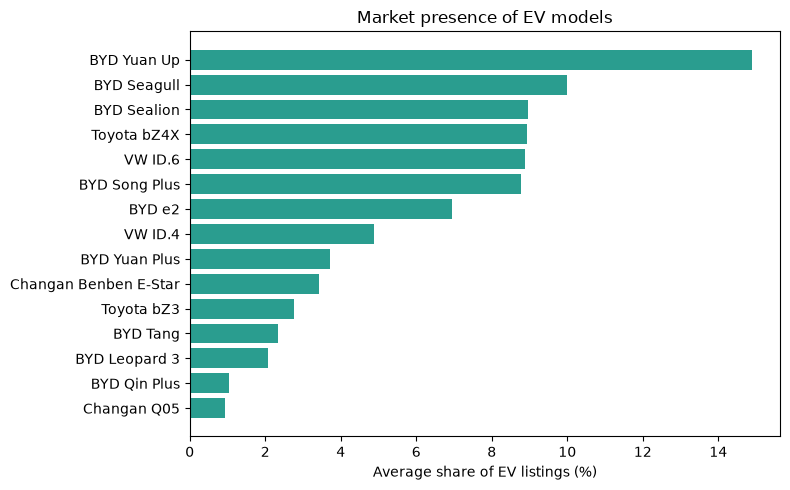

In [10]:
top = vehicles.head(15).sort_values("presence_share")
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["presence_share"] * 100, color="#2a9d8f")
plt.xlabel("Average share of EV listings (%)")
plt.title("Market presence of EV models")
plt.tight_layout()
plt.show()

## 5. Vehicle selection

**Gates:** listed on at least 3 of 5 marketplaces and at least 100 listings. The final choice comes from the
assignment's candidates (ID.4 or ID.6 count as one).

| Criterion | Measure | Weight |
|---|---|---|
| C1 Market presence | `presence_share`, scaled 0–1 | 40% |
| C2 Fleet maturity | `share_2023_or_older`, scaled 0–1 | 25% |
| C3 After-sales gap | 0 official parts dealer, 0.5 unconfirmed, 1 grey imports only | 25% |
| C4 Low market risk | 0 if the model had an import ban, else 1 | 10% |

C1–C2 come from the data; C3–C4 are judgement based on distributor news:
BYD has an official dealer with genuine parts ([Addis Standard](https://addisstandard.com/chinese-ev-giant-byd-debuts-in-ethiopia-with-five-electric-models-moenco-partnership));
VW ID cars are grey imports and were banned, then allowed again ([Addis Fortune](https://addisfortune.news/fed-lifts-chinese-assembled-volkswagen-embargo));
Toyota and Changan official EV parts channels could not be confirmed.

In [11]:
CANDIDATES = ["BYD Seagull", "BYD Yuan Up", "Changan Benben E-Star", "Toyota bZ4X", "VW ID.4", "VW ID.6"]
AFTER_SALES_GAP = {"BYD": 0.0, "Toyota": 0.5, "Changan": 0.5, "VW": 1.0}
IMPORT_BAN_HISTORY = {"VW": 1}


def min_max(series):
    return (series - series.min()) / (series.max() - series.min())


def score(table, weights):
    total = 0
    for column, weight in weights.items():
        total = total + table[column] * weight
    return total


passes_gates = (vehicles["sources_present"] >= 3) & (vehicles["listings_total"] >= 100)
ranked = vehicles[passes_gates].copy()
brand = ranked.index.str.split().str[0]

ranked["c1_presence"] = min_max(ranked["presence_share"])
ranked["c2_maturity"] = min_max(ranked["share_2023_or_older"])
ranked["c3_gap"] = brand.map(AFTER_SALES_GAP).fillna(0.5).values
ranked["c4_low_risk"] = 1 - brand.map(IMPORT_BAN_HISTORY).fillna(0).values

WEIGHTS = {"c1_presence": 0.40, "c2_maturity": 0.25, "c3_gap": 0.25, "c4_low_risk": 0.10}
ranked["score"] = score(ranked, WEIGHTS)
ranked["candidate"] = ranked.index.isin(CANDIDATES)
ranked = ranked.sort_values("score", ascending=False)

ranked[["candidate", "c1_presence", "c2_maturity", "c3_gap", "c4_low_risk", "score"]].round(2)

,candidate,c1_presence,c2_maturity,c3_gap,c4_low_risk,score
model,,,,,,
VW ID.6,True,0.57,0.81,1.0,0.0,0.68
Toyota bZ4X,True,0.58,0.82,0.5,1.0,0.66
VW ID.4,True,0.29,1.00,1.0,0.0,0.61
BYD Yuan Up,True,1.00,0.01,0.0,1.0,0.50
Changan Benben E-Star,True,0.18,0.73,0.5,1.0,0.48
BYD Seagull,True,0.65,0.08,0.0,1.0,0.38
Toyota bZ3,False,0.13,0.22,0.5,1.0,0.33
BYD Sealion,False,0.58,0.00,0.0,1.0,0.33
BYD Song Plus,False,0.56,0.01,0.0,1.0,0.33


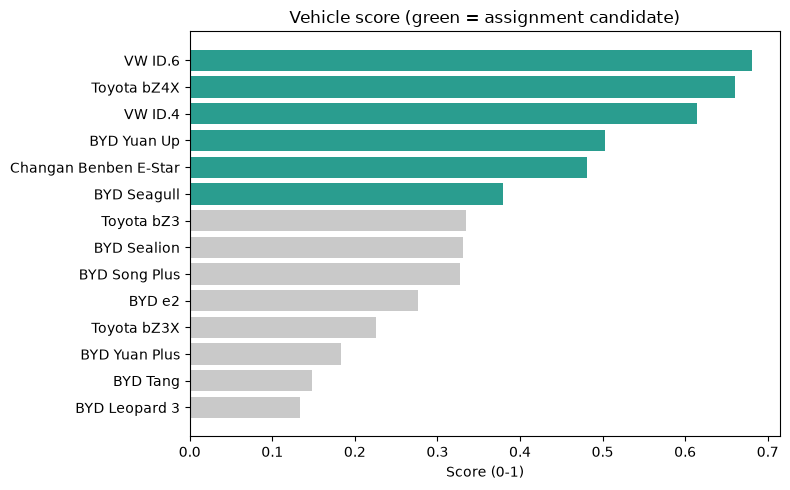

In [12]:
colors = ["#2a9d8f" if is_candidate else "#c9c9c9" for is_candidate in ranked["candidate"]]
plt.figure(figsize=(8, 5))
plt.barh(ranked.index[::-1], ranked["score"][::-1], color=colors[::-1])
plt.xlabel("Score (0-1)")
plt.title("Vehicle score (green = assignment candidate)")
plt.tight_layout()
plt.show()

### 5.1 Sensitivity

Do other weights change the three selected vehicles?

In [13]:
WEIGHT_SETS = {
    "base": WEIGHTS,
    "equal": {"c1_presence": 0.25, "c2_maturity": 0.25, "c3_gap": 0.25, "c4_low_risk": 0.25},
    "presence-heavy": {"c1_presence": 0.60, "c2_maturity": 0.20, "c3_gap": 0.10, "c4_low_risk": 0.10},
    "maturity-heavy": {"c1_presence": 0.30, "c2_maturity": 0.45, "c3_gap": 0.15, "c4_low_risk": 0.10},
    "gap-heavy": {"c1_presence": 0.30, "c2_maturity": 0.20, "c3_gap": 0.40, "c4_low_risk": 0.10},
    "data only": {"c1_presence": 0.60, "c2_maturity": 0.40, "c3_gap": 0.0, "c4_low_risk": 0.0},
}


def pick_three(scores):
    chosen = []
    for model in scores.sort_values(ascending=False).index:
        if model not in CANDIDATES:
            continue
        if model.startswith("VW") and any(m.startswith("VW") for m in chosen):
            continue
        chosen.append(model)
        if len(chosen) == 3:
            break
    return chosen


rows = []
for name, weights in WEIGHT_SETS.items():
    rows.append({"weights": name, "selected": ", ".join(pick_three(score(ranked, weights)))})
pd.DataFrame(rows)

,weights,selected
0,base,"VW ID.6, Toyota bZ4X, BYD Yuan Up"
1,equal,"Toyota bZ4X, Changan Benben E-Star, VW ID.6"
2,presence-heavy,"BYD Yuan Up, Toyota bZ4X, VW ID.6"
3,maturity-heavy,"Toyota bZ4X, VW ID.6, Changan Benben E-Star"
4,gap-heavy,"VW ID.6, Toyota bZ4X, Changan Benben E-Star"
5,data only,"Toyota bZ4X, VW ID.6, BYD Yuan Up"


### 5.2 Decision

**Selected: VW ID.6, Toyota bZ4X, BYD Yuan Up.**

* **VW ID.6** and **Toyota bZ4X** win under every weight set: high presence (about 9% each) and the oldest fleets (about 3 in 4 cars from 2023 or earlier).
* **Third place** is split between BYD Yuan Up (3 weight sets) and Changan Benben E-Star (3 weight sets).
  **Yuan Up** is chosen: it has by far the highest presence (14.9% vs 3.4%) and a BYD parts catalogue exists.
  The Benben E-Star is the reserve choice.
* **ID.6 over ID.4:** almost twice the presence (8.9% vs 4.9%).


In [14]:
ranked.to_csv(f"{OUTPUT_DIR}/vehicle_scores.csv")

### 5.3 Limitations

* No sales or registration data by model exists; presence on marketplaces is a proxy.
* Adey covers about the last 30 days of posts, so shares reflect recent activity.
* The same car can appear on several marketplaces; shares reduce but do not remove this.
* Gezat has only 10 distinct cars, some with implausible years; it counts only toward `sources_present`.
* C3 and C4 rely on news reports, not a parts-price survey.

## 6. Parts analysis

**Unit:** 30 rows = 3 vehicles × 10 parts.

Two assigned categories were replaced because almost no evidence exists for them
(4 cabin-filter and 5 wiper ads on Jiji across all cars, no EV-specific supplier data):
* wiper blades → **tyres** (EVs are heavy and wear tyres faster; most-reported failure in NHTSA data)
* cabin-air filters → **12V battery** (second most-reported failure, with recalls)

### 6.1 Load parts data

In [15]:
parts_raw = load_release(PARTS_TAG, ["parts_jiji_parts.csv", "parts_landin.csv", "parts_evprotec.csv", "parts_toyota.csv",
                                     "parts_asiautos.csv", "nhtsa_complaints.csv", "nhtsa_recalls.csv", "exchange_rates_nbe.csv"])

jiji_parts = parts_raw["parts_jiji_parts.csv"]
landin = parts_raw["parts_landin.csv"]
evprotec = parts_raw["parts_evprotec.csv"]
toyota = parts_raw["parts_toyota.csv"]
asiautos = parts_raw["parts_asiautos.csv"]
complaints = parts_raw["nhtsa_complaints.csv"]
recalls = parts_raw["nhtsa_recalls.csv"]
rates = parts_raw["exchange_rates_nbe.csv"]

parts_jiji_parts.csv         1422 rows   checksum OK


parts_landin.csv             3977 rows   checksum OK


parts_evprotec.csv            339 rows   checksum OK


parts_toyota.csv             1076 rows   checksum OK


parts_asiautos.csv            500 rows   checksum OK


nhtsa_complaints.csv         1078 rows   checksum OK


nhtsa_recalls.csv              52 rows   checksum OK


exchange_rates_nbe.csv         19 rows   checksum OK


### 6.2 Part and vehicle names

Titles are matched to a part (English and Amharic words) and to one of the three vehicles.
Accessories and small fittings (brackets, covers, bulbs, polish...) are not counted as the part.

In [16]:
VEHICLES = ["VW ID.6", "Toyota bZ4X", "BYD Yuan Up"]
PARTS = ["brake pads", "brake discs", "12V battery", "tyres", "headlights",
         "tail lights", "side mirrors", "bumpers", "fenders", "shock absorbers"]

PART_PATTERNS = [
    ("brake pads", r"brake ?pads?|pad kit|ፍሬን ሸራ"),
    ("brake discs", r"brake ?dis[ck]s?|brake rotor|disc rotor|\brotors?\b"),
    ("12V battery", r"12 ?v\b|12 ?volt|car battery|lead acid|ባትሪ"),
    ("tyres", r"\btires?\b|\btyres?\b|ጎማ"),
    ("headlights", r"head ?(light|lamp)s?|የፊት (ማ|መ)ብራት"),
    ("tail lights", r"tail ?(light|lamp)s?|rear (combination )?lamp|የ(ዋ|ኋ|ዉሃ)ላ ማብራት|ፊረቻ"),
    ("side mirrors", r"mirror|ስፖ"),
    ("bumpers", r"bumper|bunper|ፓራ(ወ|ኦ)ልት"),
    ("fenders", r"fender|ፈረፋንጎ"),
    ("shock absorbers", r"shock|strut|damper|suspension|አሞርዛተር"),
]
NOT_THE_PART = (r"bracket|grill|trim|strip|moulding|hook|reflector|deflector|spoiler|support|clip|bolt|screw|liner|seal|bulb|"
                r"washer|cap\b|sensor|camera|harness|switch|polish|restoration|inflator|pressure|gauge|charger|sticker|film|"
                r"cover|mat\b|light bar|led bar|fog|signal")
VEHICLE_PATTERNS = {"VW ID.6": r"\bid ?6\b", "Toyota bZ4X": r"bz ?4 ?x", "BYD Yuan Up": r"yuan ?up|atto ?2"}


def find_part(text):
    text = simplify(text)
    if re.search(NOT_THE_PART, text):
        return None
    for part, pattern in PART_PATTERNS:
        if re.search(pattern, text):
            return part
    return None


def find_vehicle(text):
    text = simplify(text)
    for vehicle, pattern in VEHICLE_PATTERNS.items():
        if re.search(pattern, text):
            return vehicle
    return None

### 6.3 Local parts ads (Jiji, Ethiopia)

Repeated adverts (found by several searches) are dropped by ID. Prices below 500 ETB are treated as missing.

In [17]:
local = jiji_parts.drop_duplicates("listing_id").copy()
local["part"] = local["title"].apply(find_part)
local["vehicle"] = local["title"].apply(find_vehicle)
local["price_etb"] = pd.to_numeric(local["price_value"], errors="coerce")
local.loc[local["price_etb"] < 500, "price_etb"] = None

print(len(local), "unique ads |", local["part"].notna().sum(), "match a part |",
      (local["part"].notna() & local["vehicle"].notna()).sum(), "match a part and one of our vehicles")
pd.crosstab(local["part"], local["vehicle"].fillna("other cars"))

868 unique ads | 466 match a part | 35 match a part and one of our vehicles


vehicle,BYD Yuan Up,Toyota bZ4X,VW ID.6,other cars
part,,,,
12V battery,0,2,0,37
brake discs,0,0,0,2
brake pads,0,1,1,22
bumpers,4,1,5,33
fenders,1,2,1,9
headlights,1,1,1,73
shock absorbers,0,1,1,13
side mirrors,0,0,0,15
tail lights,1,0,2,45


### 6.4 Supplier catalogues

| Vehicle | Source | Spec | Price |
|---|---|---|---|
| VW ID.6 | Landin (China), evprotec (Dubai; also parts marked ID4/ID6) | China | RMB, AED |
| Toyota bZ4X | Toyota genuine parts (France) | Europe | EUR |
| BYD Yuan Up | asiautos (China) | China | none (placeholders) |

Toyota names are generic, so parts are matched by Toyota's part-name codes (e.g. `04465` = front brake pad kit).
Prices are converted with the official National Bank of Ethiopia rate.

In [18]:
etb_rate = rates.set_index("currency")["weighted_average_etb"].astype(float)
print("NBE rates (ETB):", etb_rate[["CNY", "AED", "EUR", "USD"]].to_dict())

supplier = []

id6 = landin[landin["model"].str.contains(r"ID\.?6|ID6", regex=True, na=False)]
for _, row in id6.iterrows():
    price = None if "request" in str(row["price_text"]) else to_number(row["price_text"])
    supplier.append(["VW ID.6", find_part(row["name"]), "Landin", row["oe_number"], price, "CNY", "China"])

ev_id6 = evprotec[evprotec["category"].str.contains("id6") | evprotec["name"].str.contains("ID4/ID6", na=False)]
for _, row in ev_id6.iterrows():
    price = to_number(row["price"])
    number = row["sku"]
    if pd.isna(number):  # some items only give the number in the name: "..., Part Number: 1EA615301A"
        found = re.search(r"Part Number:\s*([A-Z0-9]{6,})", str(row["name"]))
        number = found.group(1) if found else None
    supplier.append(["VW ID.6", find_part(row["name"]), "evprotec", number, price if price else None, "AED", "China"])

TOYOTA_CODES = {
    "brake pads": ["04465", "04466"], "brake discs": ["43512", "42431"], "12V battery": ["28800"],
    "shock absorbers": ["48510", "48520", "48530", "48540"], "bumpers": ["52102", "52103", "52161", "52162"],
    "fenders": ["53811", "53812"], "headlights": ["81110", "81150"], "tail lights": ["81551", "81561"],
    "side mirrors": ["87910", "87940"],
}
for part, codes in TOYOTA_CODES.items():
    matches = toyota[toyota["item_ref"].str[:5].isin(codes) | toyota["part_no"].str[:5].isin(codes)]
    for _, row in matches.drop_duplicates("part_no").iterrows():
        price = to_number(row["price"])
        supplier.append(["Toyota bZ4X", part, "Toyota", row["part_no"], price if price else None, "EUR", "Europe"])

yuan_up = asiautos[asiautos["title"].str.contains(r"yuan ?up|atto ?2", case=False, regex=True, na=False)]
for _, row in yuan_up.iterrows():
    number = re.search(r"\b\d{8}-00\b", row["title"])
    supplier.append(["BYD Yuan Up", find_part(row["title"]), "asiautos", number.group(0) if number else None, None, None, "China"])

supplier = pd.DataFrame(supplier, columns=["vehicle", "part", "source", "part_no", "price", "currency", "spec"])
supplier = supplier[supplier["part"].notna()].copy()
supplier["price_etb"] = supplier["price"] * supplier["currency"].map(etb_rate)

pd.crosstab(supplier["part"], supplier["vehicle"])

NBE rates (ETB): {'CNY': 24.298, 'AED': 44.1061, 'EUR': 178.3752, 'USD': 161.1913}


vehicle,BYD Yuan Up,Toyota bZ4X,VW ID.6
part,,,
12V battery,0,4,0
brake discs,2,1,5
brake pads,2,2,2
bumpers,2,5,19
fenders,3,2,17
headlights,2,4,6
shock absorbers,7,6,14
side mirrors,4,4,3
tail lights,3,2,10


### 6.5 Failure frequency (NHTSA)

Share of US owner complaints that mention each part. The bZ4X has only 37 complaints, so both vehicles are
**pooled** (1,078 complaints) to avoid small-sample noise. The ID.4 stands in for the ID.6 (same platform);
the Yuan Up is not sold in the US and gets the pooled rate.

In [19]:
FAILURE_WORDS = {
    "brake pads": r"brake pads?|\bpads?\b", "brake discs": r"rotors?|brake dis[ck]s?|disc brake",
    "12V battery": r"12 ?v\b|12-volt|12 volt|auxiliary battery|low[- ]voltage battery",
    "tyres": r"\btires?\b|\btyres?\b", "headlights": r"head ?lights?|head ?lamps?",
    "tail lights": r"tail ?lights?|tail ?lamps?", "side mirrors": r"mirrors?", "bumpers": r"bumpers?",
    "fenders": r"fenders?|quarter panel", "shock absorbers": r"shock absorbers?|\bshocks?\b|struts?|dampers?",
}
NHTSA_MODEL = {"VW ID.6": "ID.4", "Toyota bZ4X": "BZ4X"}

complaint_text = (complaints["summary"].fillna("") + " " + complaints["components"].fillna("")).str.lower()
recall_text = (recalls["summary"].fillna("") + " " + recalls["component"].fillna("")).str.lower()

failure = pd.DataFrame(index=PARTS)
for model in ["BZ4X", "ID.4"]:
    model_text = complaint_text[complaints["model"] == model]
    failure[f"{model} per 100"] = [100 * model_text.str.contains(FAILURE_WORDS[p], regex=True).mean() for p in PARTS]
failure["pooled per 100"] = [100 * complaint_text.str.contains(FAILURE_WORDS[p], regex=True).mean() for p in PARTS]
failure["recalls"] = [recall_text.str.contains(FAILURE_WORDS[p], regex=True).sum() for p in PARTS]
failure.round(1).sort_values("pooled per 100", ascending=False)

,BZ4X per 100,ID.4 per 100,pooled per 100,recalls
tyres,13.5,4.9,5.2,2
12V battery,16.2,3.2,3.6,2
headlights,0.0,1.7,1.7,1
bumpers,13.5,0.9,1.3,0
fenders,8.1,0.3,0.6,0
side mirrors,2.7,0.6,0.6,0
shock absorbers,0.0,0.6,0.6,0
brake pads,5.4,0.3,0.5,0
tail lights,0.0,0.2,0.2,0
brake discs,0.0,0.1,0.1,0


### 6.6 Commonness

A common part lets one stock item serve more cars. It is measured two ways:
* **Generic part type:** share of local ads for the part that name no car (sold by size or specification, e.g. tyres, batteries).
* **Shared part number:** the catalogue part number for our vehicle is also listed for another EV model (e.g. ID.6 and ID.4).

In [20]:
CAR_WORDS = (r"toyota|suzuki|hyundai|byd|volkswagen|\bvw\b|nissan|kia|mercedes|benz|honda|chevrolet|ford|mitsubishi|"
             r"isuzu|jetour|chery|changan|geely|lifan|jeep|gmc|tesla|bmw|audi|mazda|peugeot|renault|dongfeng|neta|"
             r"leapmotor|aion|\bid ?\d\b|bz ?\d|yuan|seagull|dolphin|sealion|\be2\b|vitz|corolla|yaris|hilux|rav4|"
             r"dzire|swift|tucson|elantra|creta|accent|picanto|tacoma|land cruiser|prado|camry|x70|captiva|qashqai|"
             r"patrol|sunny|atos|i10|alsvin|e ?star|q05")

local["names_a_car"] = local["title"].apply(lambda title: bool(re.search(CAR_WORDS, simplify(title))))
generic_share = 1 - local[local["part"].notna()].groupby("part")["names_a_car"].mean()

# VW: OE numbers listed for both ID.6 and ID.4 (Landin) + evprotec parts sold as "ID4/ID6"
landin["part"] = landin["name"].apply(find_part)
id6_numbers = set(landin.loc[landin["model"].str.contains(r"ID\.?6|ID6", regex=True, na=False), "oe_number"].dropna())
id4_numbers = set(landin.loc[landin["model"].str.contains(r"ID\.?4|ID4", regex=True, na=False), "oe_number"].dropna())
vw_shared = set(landin.loc[landin["oe_number"].isin(id6_numbers & id4_numbers), "part"].dropna())
vw_shared |= set(evprotec.loc[evprotec["name"].str.contains("ID4/ID6", na=False), "name"].apply(find_part).dropna())

# BYD: Yuan Up part numbers that also appear for another BYD model
asiautos["number"] = asiautos["title"].str.extract(r"\b(\d{8}-00)\b")[0]
is_yuan_up = asiautos["title"].str.contains(r"yuan ?up|atto ?2", case=False, regex=True, na=False)
byd_numbers = set(asiautos.loc[is_yuan_up, "number"].dropna()) & set(asiautos.loc[~is_yuan_up, "number"].dropna())
byd_shared = set(asiautos.loc[is_yuan_up & asiautos["number"].isin(byd_numbers), "title"].apply(find_part).dropna())

SHARED_PARTS = {"VW ID.6": vw_shared, "BYD Yuan Up": byd_shared, "Toyota bZ4X": set()}  # only the bZ4X catalogue was collected

print("Shared part numbers:", {vehicle: sorted(parts) for vehicle, parts in SHARED_PARTS.items()})
generic_share.round(2).sort_values(ascending=False).rename("share of ads naming no car").to_frame()

Shared part numbers: {'VW ID.6': ['brake discs', 'brake pads', 'shock absorbers', 'side mirrors'], 'BYD Yuan Up': [], 'Toyota bZ4X': []}


,share of ads naming no car
part,
12V battery,0.87
tyres,0.63
brake discs,0.50
shock absorbers,0.47
side mirrors,0.33
brake pads,0.21
headlights,0.17
bumpers,0.14
fenders,0.08


### 6.7 Parts table (30 rows)

In [21]:
rows = []
for vehicle in VEHICLES:
    for part in PARTS:
        ads = local[(local["vehicle"] == vehicle) & (local["part"] == part)]
        sup = supplier[(supplier["vehicle"] == vehicle) & (supplier["part"] == part)]
        model = NHTSA_MODEL.get(vehicle)
        own_complaints = complaint_text[complaints["model"] == model].str.contains(FAILURE_WORDS[part], regex=True).sum() if model else 0
        own_recalls = recall_text[recalls["model"] == model].str.contains(FAILURE_WORDS[part], regex=True).sum() if model else 0
        rows.append({
            "vehicle": vehicle,
            "part": part,
            "local_ads": len(ads),
            "local_price_etb": ads["price_etb"].median(),
            "supplier_price_etb": sup["price_etb"].median(),
            "catalogue_spec": sup["spec"].iloc[0] if sup["part_no"].notna().any() else None,
            "part_numbers": sup["part_no"].dropna().nunique(),
            "own_complaints": own_complaints,
            "own_recalls": own_recalls,
            "shared_part_number": part in SHARED_PARTS[vehicle],
        })
parts_table = pd.DataFrame(rows)
parts_table.to_csv(f"{OUTPUT_DIR}/parts_table.csv", index=False)
parts_table

,vehicle,part,local_ads,local_price_etb,supplier_price_etb,catalogue_spec,part_numbers,own_complaints,own_recalls,shared_part_number
0,VW ID.6,brake pads,1,44999.0,NaN,China,1,3,0,True
1,VW ID.6,brake discs,0,NaN,NaN,China,3,1,0,True
2,VW ID.6,12V battery,0,NaN,NaN,NaN,0,33,2,False
3,VW ID.6,tyres,5,25000.0,80052.571500,China,1,51,0,False
4,VW ID.6,headlights,1,70000.0,231557.025000,China,4,18,1,False
5,VW ID.6,tail lights,2,80000.0,172013.790000,China,9,2,0,False
6,VW ID.6,side mirrors,0,NaN,32197.453000,China,3,6,0,True
7,VW ID.6,bumpers,5,240000.0,82037.346000,China,19,9,0,False
8,VW ID.6,fenders,1,75000.0,64741.949000,China,15,3,0,False
9,VW ID.6,shock absorbers,1,65000.0,92887.446600,China,8,6,0,True


### 6.8 Criteria and score

| Criterion | Measure | Becomes a number by | Weight |
|---|---|---|---|
| C1 Failure frequency | Pooled NHTSA complaints mentioning the part | min-max over parts | 20% |
| C2 Local market demand | Local ads for the part (all cars) | min-max over parts | 10% |
| C3 Vehicle demand | Presence + fleet maturity from section 5 | average of the two scaled values | 15% |
| C4 Local scarcity | Local ads for this vehicle and part | 1 − ads / max ads | 15% |
| C5 Price margin | Local price ÷ landed cost | ratio ≥ 2 → 1, ratio 1 → 0.5; missing → 0.5 | 10% |
| C6 Fitment | Catalogue part number | China spec 1, other spec 0.5, none 0 | 5% |
| C7 Evidence | Sources supporting the row (local ads, price, part number, own complaints, recall) | count / 5 | 5% |
| C8 Commonness | Generic part type + shared part number | generic share, + 0.25 if the part number is shared with another EV model (max 1) | 20% |

**Why these weights:** failure, demand and commonness carry most weight because the client cannot stock every
part for every vehicle, so it needs parts that break often and serve many cars. Margin and fitment rely on
assumptions or partial data, so they weigh less.

**Assumption (C5):** landed cost = supplier price × 1.35 (small parts), 1.5 (medium) or 1.8 (bulky: tyres, bumpers, fenders),
covering duty, taxes and shipping. Missing margins get the neutral value 0.5, not 0.

In [22]:
SIZE = {"brake pads": "small", "12V battery": "medium", "brake discs": "medium", "shock absorbers": "medium",
        "headlights": "medium", "tail lights": "medium", "side mirrors": "medium",
        "tyres": "bulky", "bumpers": "bulky", "fenders": "bulky"}
LANDED_FACTOR = {"small": 1.35, "medium": 1.5, "bulky": 1.8}

pooled_failure = failure["pooled per 100"]
market_ads = local[local["part"].notna()].groupby("part").size().reindex(PARTS, fill_value=0)
vehicle_demand = (ranked["c1_presence"] + ranked["c2_maturity"]) / 2

t = parts_table
t["c1_failure"] = t["part"].map(min_max(pooled_failure))
t["c2_market"] = t["part"].map(min_max(market_ads))
t["c3_vehicle"] = t["vehicle"].map(vehicle_demand)
t["c4_scarcity"] = 1 - t["local_ads"] / t["local_ads"].max()
landed_cost = t["supplier_price_etb"] * t["part"].map(SIZE).map(LANDED_FACTOR)
t["margin_ratio"] = t["local_price_etb"] / landed_cost
t["c5_margin"] = (t["margin_ratio"].clip(upper=2) / 2).fillna(0.5)
t["c6_fitment"] = t["catalogue_spec"].map({"China": 1.0, "Europe": 0.5}).fillna(0.0)
t["c7_evidence"] = ((t["local_ads"] > 0).astype(int) + t["supplier_price_etb"].notna().astype(int)
                    + (t["part_numbers"] > 0).astype(int) + (t["own_complaints"] > 0).astype(int)
                    + (t["own_recalls"] > 0).astype(int)) / 5
t["c8_commonness"] = (t["part"].map(generic_share).fillna(0) + 0.25 * t["shared_part_number"].astype(int)).clip(upper=1)

PART_WEIGHTS = {"c1_failure": 0.20, "c2_market": 0.10, "c3_vehicle": 0.15, "c4_scarcity": 0.15,
                "c5_margin": 0.10, "c6_fitment": 0.05, "c7_evidence": 0.05, "c8_commonness": 0.20}
t["score"] = score(t, PART_WEIGHTS)
t["item"] = t["vehicle"] + " – " + t["part"]

criteria = list(PART_WEIGHTS)
t.sort_values("score", ascending=False)[["item"] + criteria + ["score"]].round(2).head(10)

,item,c1_failure,c2_market,c3_vehicle,c4_scarcity,c5_margin,c6_fitment,c7_evidence,c8_commonness,score
13,Toyota bZ4X – tyres,1.00,1.00,0.70,0.6,0.50,0.0,0.6,0.63,0.70
2,VW ID.6 – 12V battery,0.69,0.20,0.69,1.0,0.50,0.0,0.4,0.87,0.66
23,BYD Yuan Up – tyres,1.00,1.00,0.51,0.6,0.50,0.0,0.2,0.63,0.65
3,VW ID.6 – tyres,1.00,1.00,0.69,0.0,0.09,1.0,0.8,0.63,0.63
12,Toyota bZ4X – 12V battery,0.69,0.20,0.70,0.6,0.29,0.5,0.8,0.87,0.62
22,BYD Yuan Up – 12V battery,0.69,0.20,0.51,1.0,0.50,0.0,0.0,0.87,0.61
6,VW ID.6 – side mirrors,0.11,0.07,0.69,1.0,0.50,1.0,0.6,0.58,0.53
1,VW ID.6 – brake discs,0.00,0.00,0.69,1.0,0.50,1.0,0.4,0.75,0.52
9,VW ID.6 – shock absorbers,0.09,0.07,0.69,0.8,0.23,1.0,0.8,0.72,0.51
17,Toyota bZ4X – bumpers,0.24,0.22,0.70,0.8,0.92,0.5,0.8,0.14,0.48


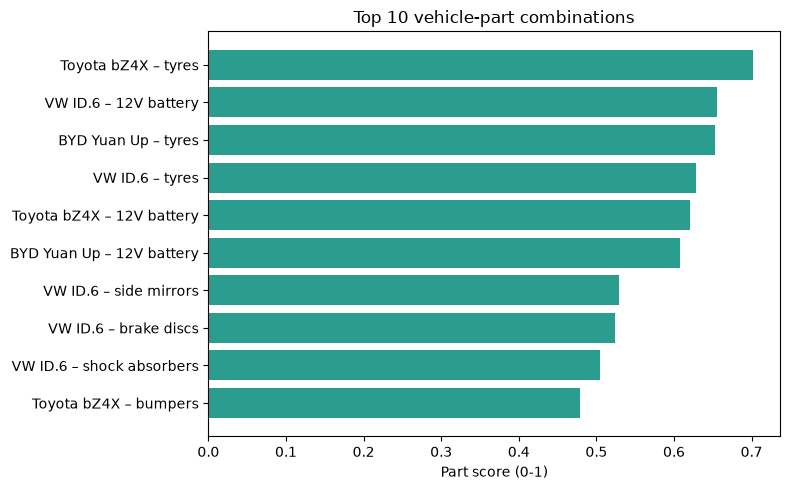

In [23]:
top10 = t.sort_values("score", ascending=False).head(10)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top10["item"], top10["score"], color="#2a9d8f")
plt.xlabel("Part score (0-1)")
plt.title("Top 10 vehicle-part combinations")
plt.tight_layout()
plt.show()

### 6.9 Sensitivity

The top 5 is recalculated with other weight sets, with each criterion removed in turn, and with missing margins set to 0.

In [24]:
PART_WEIGHT_SETS = {
    "base": PART_WEIGHTS,
    "equal": {c: 1 / len(criteria) for c in criteria},
    "demand-heavy": {"c1_failure": 0.30, "c2_market": 0.15, "c3_vehicle": 0.20, "c4_scarcity": 0.10,
                     "c5_margin": 0.05, "c6_fitment": 0.05, "c7_evidence": 0.05, "c8_commonness": 0.10},
    "opportunity-heavy": {"c1_failure": 0.10, "c2_market": 0.10, "c3_vehicle": 0.10, "c4_scarcity": 0.30,
                          "c5_margin": 0.20, "c6_fitment": 0.05, "c7_evidence": 0.05, "c8_commonness": 0.10},
    "commonness-heavy": {"c1_failure": 0.15, "c2_market": 0.10, "c3_vehicle": 0.10, "c4_scarcity": 0.10,
                         "c5_margin": 0.05, "c6_fitment": 0.05, "c7_evidence": 0.05, "c8_commonness": 0.40},
}
for removed in criteria:
    kept = {c: w for c, w in PART_WEIGHTS.items() if c != removed}
    PART_WEIGHT_SETS[f"without {removed}"] = {c: w / sum(kept.values()) for c, w in kept.items()}

no_margin = t.copy()
no_margin["c5_margin"] = (no_margin["margin_ratio"].clip(upper=2) / 2).fillna(0)
scenarios = {name: score(t, weights) for name, weights in PART_WEIGHT_SETS.items()}
scenarios["missing margin = 0"] = score(no_margin, PART_WEIGHTS)

top_items, top_parts = [], []
for scores in scenarios.values():
    top_items += t.loc[scores.sort_values(ascending=False).index[:5], "item"].tolist()
    top_parts += scores.groupby(t["part"]).mean().sort_values(ascending=False).index[:5].tolist()

column = f"% of {len(scenarios)} scenarios in top 5"
item_robustness = (pd.Series(top_items).value_counts() / len(scenarios) * 100).round(0).astype(int).rename(column)
part_robustness = (pd.Series(top_parts).value_counts() / len(scenarios) * 100).round(0).astype(int).rename(column)

print("Vehicle-part items:")
display(item_robustness.to_frame().head(8))
print("Part types (average over the three vehicles):")
display(part_robustness.to_frame())

Vehicle-part items:


,% of 14 scenarios in top 5
Toyota bZ4X – tyres,100
VW ID.6 – 12V battery,93
BYD Yuan Up – tyres,79
VW ID.6 – tyres,71
Toyota bZ4X – 12V battery,64
BYD Yuan Up – 12V battery,36
VW ID.6 – side mirrors,21
Toyota bZ4X – bumpers,14


Part types (average over the three vehicles):


,% of 14 scenarios in top 5
tyres,100
12V battery,100
shock absorbers,93
side mirrors,93
brake discs,57
headlights,43
bumpers,7
brake pads,7


### 6.10 Recommendation

**Five highest-priority parts:**

| Rank | Part | In top 5 of 14 scenarios | Main reasons |
|---|---|---|---|
| 1 | **Tyres** | 100% | Most-reported EV failure; most local ads; sold by size, so one stock item fits many cars |
| 2 | **12V battery** | 100% | Second most-reported failure, with recalls; 87% of local ads name no car (generic) |
| 3 | **Shock absorbers** | 93% | Generic part type; ID.6 shocks also fit the ID.4; few local ads for our vehicles |
| 4 | **Side mirrors** | 93% | No local ads for our vehicles; ID.6 mirrors shared with the ID.4 |
| 5 | **Brake discs** | 57% | Generic part type, shared ID.4/ID.6; headlights are close behind (43%) |

**First stock items:** Toyota bZ4X tyres, VW ID.6 12V battery, BYD Yuan Up tyres, VW ID.6 tyres, Toyota bZ4X 12V battery.

Bumpers, fenders and tail lights have strong local demand but fit only one model each, so they carry
more inventory risk for a new importer. Rank 5 is the least certain.


In [25]:
by_part = t.groupby("part")["score"].mean().sort_values(ascending=False).round(2)
print("Average score per part type (base weights):")
print(by_part.to_string())

t.to_csv(f"{OUTPUT_DIR}/parts_scores.csv", index=False)

Average score per part type (base weights):
part
tyres              0.66
12V battery        0.63
shock absorbers    0.48
side mirrors       0.47
brake discs        0.47
headlights         0.45
brake pads         0.43
bumpers            0.39
tail lights        0.37
fenders            0.35


### 6.11 Limitations

* NHTSA complaints are US reports, not replacement rates, and under-count collision damage.
* Few local ads name our three vehicles (scarcity is based on small counts).
* Supplier prices mix wholesale (China), retail (Dubai) and genuine (Europe) sources; the landed-cost factors are assumptions.
* No supplier prices for the Yuan Up; its margin is neutral (0.5).
* Toyota prices and part numbers are for European bZ4X builds; Ethiopian bZ4X are often China-built.
* Tyres are sold by size, not by model, so tyre fitment evidence is weak.
* Shared part numbers could only be checked where catalogues list several models (VW ID.4/ID.6, BYD); none were found
  for the bZ4X because only its own catalogue was collected.
* The Yuan Up part numbers come from an earlier same-day request to asiautos; later requests were rate limited.